In [104]:
# 1. Setup

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_curve, auc, classification_report, confusion_matrix, roc_auc_score
from sklearn.inspection import permutation_importance
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (precision_score, recall_score,
                             f1_score, accuracy_score)


plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 10,
})

RED = '#D9534F'
BLUE = '#4682B4'
GREEN = '#2E8B57'
ORANGE = '#F0AD4E'
GRAY = '#888888'

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

df = pd.read_csv('~/Desktop/Employee-Attrition- Portfolio/data/cleaned_employee_attrition.csv')

PAST_ATTRITION = 'attrition'
OVERALL_RATE = df[PAST_ATTRITION].mean()


ACTIONABLE = [
    'job_opportunities', 'deserved_promotion',
    'rewards_wages_satisfaction', 'job_satisfaction',
    'emotional_commitment', 'job_stability',
    'job_engagement', 'work_life_balance',
    'psychological_exhaustion', 'recognition',
    'job_support', 'environment_satisfaction',
    'useful_training', 'physical_stress', 'health_issues',
    'training_status_ord', 'unpaid_overtime'
]

STRUCTURAL = [
    'age_mid', 'gender', 'marital_married', 'marital_divorced',
    'academic_degree', 'distance_to_work',
    'years_experience_mid',
    'monthly_salary_mid'
]

CORE = [
    'job_opportunities', 'job_stability', 'deserved_promotion',
    'emotional_commitment', 'rewards_wages_satisfaction', 'job_satisfaction'
]

EXCLUDE = ['id', PAST_ATTRITION] \
          + [c for c in df.columns if c.endswith('_raw')] \
          + [c for c in df.columns if c.endswith('_missing')] \
          + ['isco_2digit', 'isco_major', 'ot_status_label', 'training_status'] \
          + ['years_last_org_mid'] # in case target leaking

REDUNDANT = [
    'years_last_org', 'years_experience', 'age', 'monthly_salary',
    'ot_3', 'training_programs'
]

# modeling features: keeping numeric/ binary/ ordinal
FEATURES = [c for c in ACTIONABLE + STRUCTURAL if c in df.columns]
FEATURES = [c for c in FEATURES if df[c].nunique() > 1]

CORE = [c for c in CORE if c in FEATURES]

print(df[FEATURES].dtypes.value_counts())
missing = df[FEATURES + [PAST_ATTRITION]].isnull().sum()
missing = missing[missing > 0]
print(missing if len(missing) else "No missing values.")

int64      23
float64     2
Name: count, dtype: int64
No missing values.


 VIF (VIF > 10 = concern)
                variable  VIF
        job_satisfaction 1.89
             job_support 1.82
psychological_exhaustion 1.71
environment_satisfaction 1.67
    emotional_commitment 1.64
         physical_stress 1.56
    years_experience_mid 1.52
                 age_mid 1.50
      monthly_salary_mid 1.39
     training_status_ord 1.34
       work_life_balance 1.27
         academic_degree 1.25
          job_engagement 1.20
        distance_to_work 1.11

High VIF variables（dropped from Logit）: []
Forced drop: marital_divorced

formula:
attrition ~ job_opportunities + deserved_promotion + rewards_wages_satisfaction + job_satisfaction + emotional_commitment + job_stability + job_engagement + work_life_balance + psychological_exhaustion + recognition + job_support + environment_satisfaction + useful_training + physical_stress + health_issues + training_status_ord + unpaid_overtime + age_mid + academic_degree + distance_to_work + years_experience_mid + monthly_salary_mid 

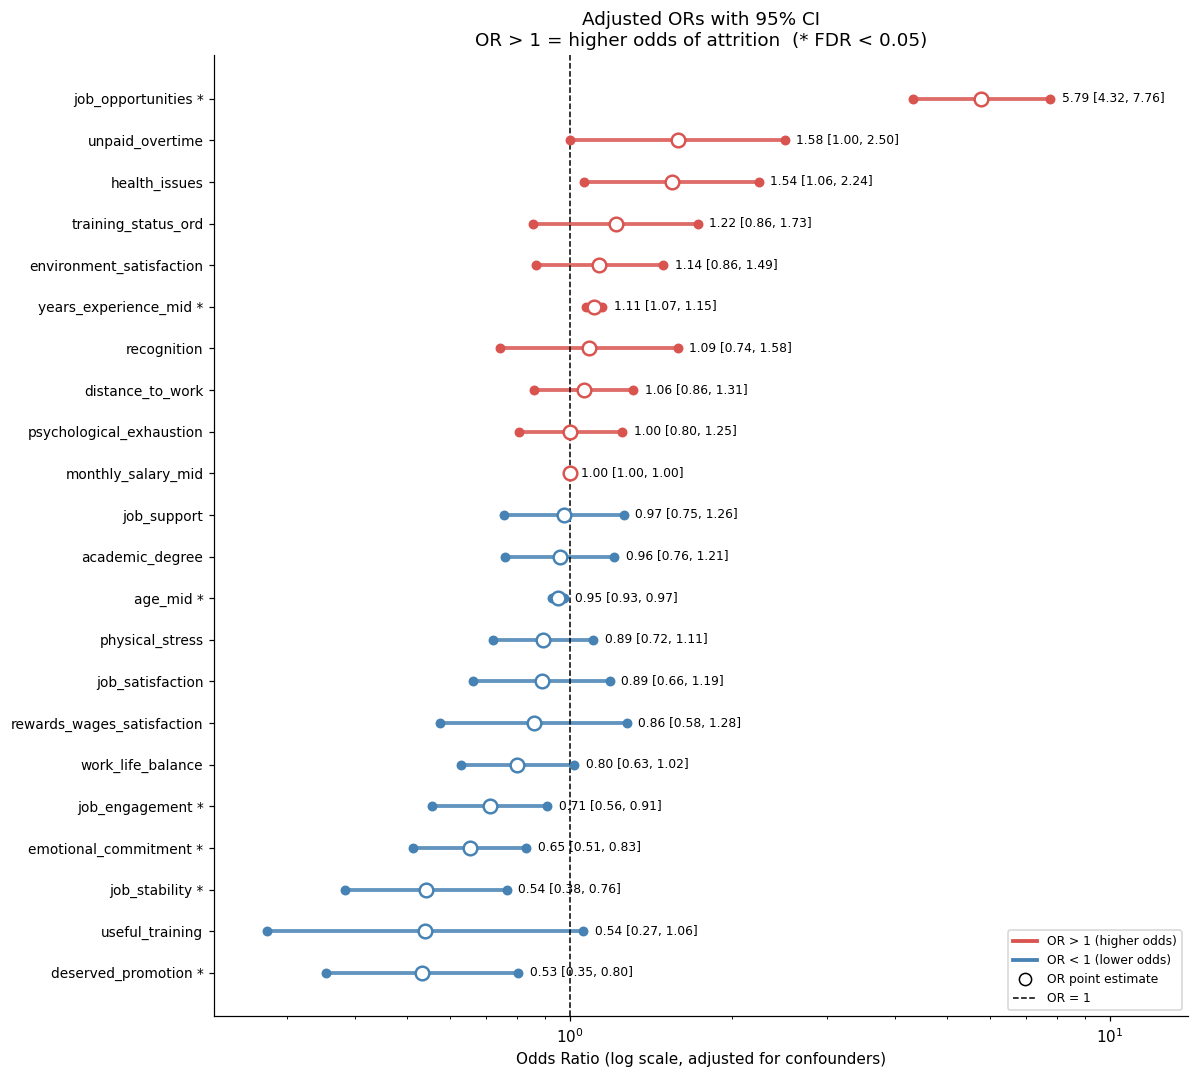

In [105]:
# 2. VIF, Logit, OR forest plot

from matplotlib.lines import Line2D


# VIF
VIF_COLS = [c for c in FEATURES if df[c].nunique() > 2]

vif_data = df[VIF_COLS].dropna()
vif_df = pd.DataFrame({
    'variable': vif_data.columns,
    'VIF': [variance_inflation_factor(vif_data.values, i)
            for i in range(vif_data.shape[1])]
}).sort_values('VIF', ascending=False).reset_index(drop=True)

print(" VIF (VIF > 10 = concern)")
print(vif_df.round(2).to_string(index=False))

HIGH_VIF = vif_df[vif_df['VIF'] > 10]['variable'].tolist()
print(f"\nHigh VIF variables（dropped from Logit）: {HIGH_VIF}")

ACTIONABLE_FINAL = [c for c in ACTIONABLE if c not in HIGH_VIF]
STRUCTURAL_FINAL = [c for c in STRUCTURAL if c not in HIGH_VIF]

# Logistic + FDR 
NUM_CTRL = [c for c in STRUCTURAL_FINAL if df[c].nunique() > 2]
CAT_CTRL = [c for c in STRUCTURAL_FINAL if df[c].nunique() <= 2]

# marital_married / marital_divorced are collinear, keep one
if 'marital_married' in CAT_CTRL and 'marital_divorced' in CAT_CTRL:
    CAT_CTRL.remove('marital_divorced')
    print("Forced drop: marital_divorced")

formula = (f"{PAST_ATTRITION} ~ " +
           " + ".join(ACTIONABLE_FINAL + NUM_CTRL) +
           (" + " + " + ".join([f"C({c})" for c in CAT_CTRL]) if CAT_CTRL else ""))

print("\nformula:")
print(formula)

model = smf.logit(formula, data=df).fit(disp=0)

coef = pd.DataFrame({
    'OR':      np.exp(model.params),
    'CI_low':  np.exp(model.conf_int()[0]),
    'CI_high': np.exp(model.conf_int()[1]),
    'p':       model.pvalues
})

mask = coef.index.isin(ACTIONABLE_FINAL + NUM_CTRL)
coef.loc[mask, 'p_fdr'] = multipletests(
    coef.loc[mask, 'p'], method='fdr_bh')[1]

coef_core = coef.loc[mask].sort_values('p_fdr')

sep_vars  = coef_core[(coef_core['CI_high'] == np.inf) | (coef_core['CI_low'] == 0)].index.tolist()
coef_show = coef_core.drop(index=sep_vars)

if sep_vars:
    print(f"[NOTE] Quasi-separated (excluded): {sep_vars}")
print("\n Adjusted ORs (FDR corrected)")
print(coef_core.round(3).to_string())

# OR dumbbell plot

plot_data = (coef_show
             .reset_index()
             .rename(columns={'index': 'variable'})
             .sort_values('OR', ascending=True)
             .reset_index(drop=True))
y_pos = np.arange(len(plot_data))
fig, ax = plt.subplots(figsize=(11, max(6, len(plot_data) * 0.45)))

for i, row in plot_data.iterrows():
    color = RED if row['OR'] > 1 else BLUE

    ax.hlines(i, row['CI_low'], row['CI_high'],
              color=color, lw=2.5, alpha=0.85, zorder=2)
    ax.scatter(row['CI_low'],  i, color=color, s=30, zorder=3)
    ax.scatter(row['CI_high'], i, color=color, s=30, zorder=3)
    ax.scatter(row['OR'], i,
               facecolors='white', edgecolors=color,
               s=80, linewidths=1.6, zorder=4)

    ax.text(row['CI_high'] * 1.05, i,
            f"{row['OR']:.2f} [{row['CI_low']:.2f}, {row['CI_high']:.2f}]",
            va='center', fontsize=8)

ax.axvline(1, color='black', ls='--', lw=1)

labels = [f"{v} *" if p < 0.05 else v
          for v, p in zip(plot_data['variable'], plot_data['p_fdr'])]

ax.set_yticks(np.arange(len(plot_data)))
ax.set_yticklabels(labels, fontsize=9)

ax.set_xscale('log')
ax.set_xlabel('Odds Ratio (log scale, adjusted for confounders)')
ax.set_title('Adjusted ORs with 95% CI\nOR > 1 = higher odds of attrition  (* FDR < 0.05)')


xmin = plot_data['CI_low'].min()
xmax = plot_data['CI_high'].max()
ax.set_xlim(xmin * 0.8, xmax * 1.8)

legend_elements = [
    Line2D([0], [0], color=RED,  lw=2.5, label='OR > 1 (higher odds)'),
    Line2D([0], [0], color=BLUE, lw=2.5, label='OR < 1 (lower odds)'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='white',
           markeredgecolor='black', markersize=8, label='OR point estimate'),
    Line2D([0], [0], color='black', ls='--', lw=1, label='OR = 1'),
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=8)

plt.tight_layout()
plt.show()

CART n = 1191  &  features = 24

 CART decision rules 
|--- job_opportunities <= 0.500
|   |--- deserved_promotion <= 0.500
|   |   |--- job_engagement <= 1.500
|   |   |   |--- class: 1
|   |   |--- job_engagement >  1.500
|   |   |   |--- class: 0
|   |--- deserved_promotion >  0.500
|   |   |--- health_issues <= 0.500
|   |   |   |--- class: 0
|   |   |--- health_issues >  0.500
|   |   |   |--- class: 0
|--- job_opportunities >  0.500
|   |--- years_experience_mid <= 5.000
|   |   |--- emotional_commitment <= 2.500
|   |   |   |--- class: 1
|   |   |--- emotional_commitment >  2.500
|   |   |   |--- class: 0
|   |--- years_experience_mid >  5.000
|   |   |--- job_stability <= 0.500
|   |   |   |--- class: 1
|   |   |--- job_stability >  0.500
|   |   |   |--- class: 1


 Leaf-level attrition profiles 
 leaf   n  n_attrition  attrition_rate  lift_vs_overall
   13 173          148           0.855             1.98
   14 191          112           0.586             1.36
    3  94      

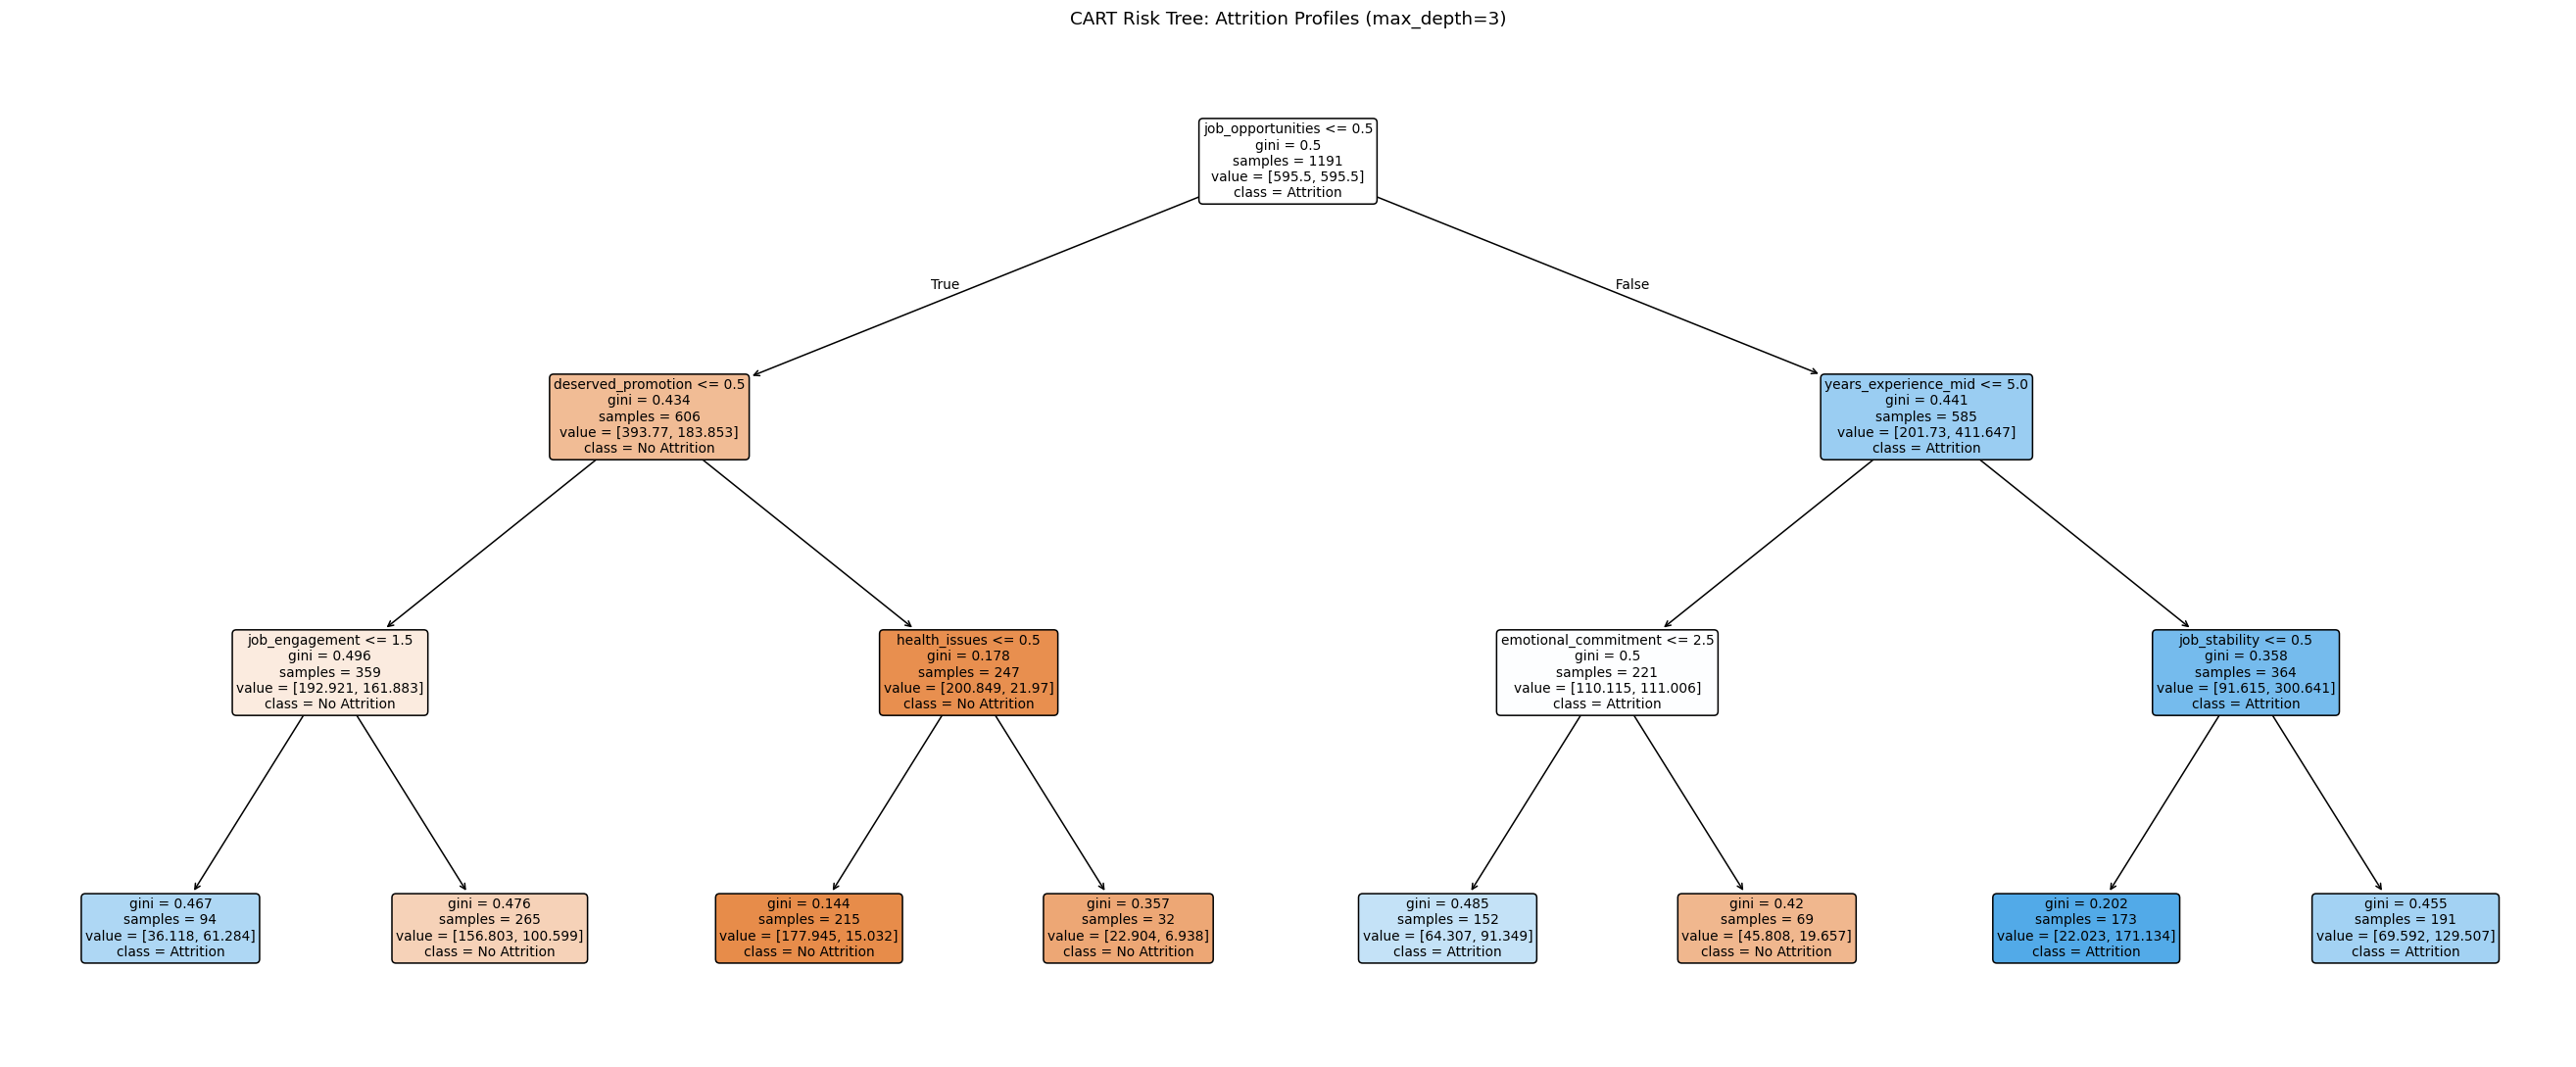

In [106]:
# 3. CART（Risk Profiles）

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

cart_cols = ACTIONABLE_FINAL + NUM_CTRL + CAT_CTRL
cart_cols = [c for c in cart_cols if c in df.columns]

X_cart = df[cart_cols].dropna().copy()
y_cart = df.loc[X_cart.index, PAST_ATTRITION]

cart = DecisionTreeClassifier(
    max_depth=3,
    min_samples_leaf=30,
    min_samples_split=60,
    class_weight='balanced',
    random_state=42
)
cart.fit(X_cart, y_cart)

print(f"CART n = {len(X_cart)}  &  features = {len(cart_cols)}")

print("\n CART decision rules ")
print(export_text(cart, feature_names=cart_cols, decimals=3))

leaf_ids = cart.apply(X_cart)
leaf_summary = (
    pd.DataFrame({'leaf': leaf_ids, 'attrition': y_cart.values})
      .groupby('leaf')
      .agg(n=('attrition', 'size'),
           n_attrition=('attrition', 'sum'),
           attrition_rate=('attrition', 'mean'))
      .reset_index()
      .sort_values('attrition_rate', ascending=False)
)
leaf_summary['lift_vs_overall'] = (leaf_summary['attrition_rate'] / OVERALL_RATE).round(2)
leaf_summary['attrition_rate'] = leaf_summary['attrition_rate'].round(3)

print("\n Leaf-level attrition profiles ")
print(leaf_summary.to_string(index=False))


fig, ax = plt.subplots(figsize=(24, 10))
plot_tree(
    cart,
    feature_names=cart_cols,
    class_names=['No Attrition', 'Attrition'],
    filled=True,
    rounded=True,
    fontsize=9,
    ax=ax
)
plt.title('CART Risk Tree: Attrition Profiles (max_depth=3)')
plt.tight_layout()
plt.show()

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)


 Formal interaction tests 
                         subgroup                      driver                      buffer    n  driver_r  OR_interaction      p  p_fdr    pattern
0  medical sector x professionals               job_stability    psychological_exhaustion  173    -0.334    6.549000e+00  0.000  0.001     buffer
1                clerical support  rewards_wages_satisfaction                 recognition  192    -0.317    7.300000e-02  0.002  0.004  intensify
2                clerical support          deserved_promotion  rewards_wages_satisfaction  192    -0.358    0.000000e+00  1.000  1.000         ns
3                        managers               job_stability           job_opportunities  132    -0.346    2.010031e+12  1.000  1.000         ns

 Pattern distribution 
pattern
ns           2
buffer       1
intensify    1
Name: count, dtype: int64


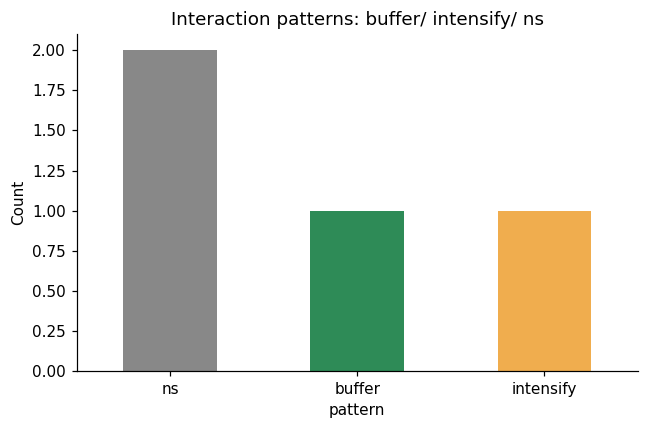

In [107]:
# 4. Formal Interaction Test（buffer/ intensify)

import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from scipy.stats import spearmanr
import pandas as pd, numpy as np

if 'combo' not in df.columns:
    df['combo'] = df['sector_group'].astype(str) + ' x ' + df['major_group_isco'].astype(str)

def formal_interaction_test(df, subgroup_col, subgroup, driver, buffer, min_n=50):
    sub = df[df[subgroup_col] == subgroup].dropna(
        subset=[driver, buffer, PAST_ATTRITION]
    ).copy()

    if len(sub) < min_n:
        return None
    if sub[driver].nunique() < 2 or sub[buffer].nunique() < 2:
        return None

    formula = f"{PAST_ATTRITION} ~ {driver} * {buffer}"
    try:
        model = smf.logit(formula, data=sub).fit(disp=0, maxiter=2000)
    except Exception:
        return None

    term = f"{driver}:{buffer}"
    if term not in model.params:
        term = f"{buffer}:{driver}"
    if term not in model.params:
        return None

    coef = model.params[term]
    p = model.pvalues[term]
    or_ = np.exp(coef)
    ci = np.exp(model.conf_int().loc[term])

    driver_r = spearmanr(sub[driver], sub[PAST_ATTRITION])[0]

    if p >= 0.05:
        pattern = 'ns'
    elif driver_r > 0:
        pattern = 'buffer' if coef < 0 else 'amplify'
    else:
        pattern = 'buffer' if coef > 0 else 'intensify'
    sep_flag = (ci[0] == 0) | (ci[1] == np.inf)
    return {
        'subgroup_col': subgroup_col,
        'subgroup': subgroup,
        'driver': driver,
        'buffer': buffer,
        'n': len(sub),
        'driver_r': round(driver_r, 3),
        'interaction_coef': round(coef, 3),
        'OR_interaction': round(or_, 3),
        'OR_lower': round(ci[0], 3),
        'OR_upper': round(ci[1], 3),
        'p': p,
        'pattern': pattern,
    }


INTERACTION_CANDIDATES = [
    ('major_group_isco', 'clerical support', 'deserved_promotion', 'rewards_wages_satisfaction'), 
    ('major_group_isco', 'managers', 'job_stability', 'job_opportunities'),                      
    ('major_group_isco', 'clerical support', 'rewards_wages_satisfaction', 'recognition'),       
    ('combo', 'medical sector x professionals', 'job_stability', 'psychological_exhaustion'), 
]


rows = []
for subgroup_col, subgroup, driver, buffer in INTERACTION_CANDIDATES:
    res = formal_interaction_test(df, subgroup_col, subgroup, driver, buffer, min_n=50)
    if res is not None:
        rows.append(res)

interaction_df = pd.DataFrame(rows)

if not interaction_df.empty:
    interaction_df['p_fdr'] = multipletests(interaction_df['p'], method='fdr_bh')[1]
    interaction_df = interaction_df.sort_values('p_fdr').reset_index(drop=True)

    print(" Formal interaction tests ")
    print(interaction_df[['subgroup', 'driver', 'buffer', 'n', 'driver_r',
                          'OR_interaction', 'p', 'p_fdr', 'pattern']].round(3).to_string())

    pattern_colors = {'buffer': GREEN,
                      'intensify': ORANGE, 'ns': GRAY}
    pattern_counts = interaction_df['pattern'].value_counts()
    print("\n Pattern distribution ")
    print(pattern_counts)
    bar_colors = [pattern_colors.get(p, GRAY) for p in pattern_counts.index]
    fig, ax = plt.subplots(figsize=(6, 4))
    pattern_counts.plot(kind='bar', color=bar_colors, ax=ax)
    ax.set_title('Interaction patterns: buffer/ intensify/ ns')
    ax.set_ylabel('Count')
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
else:
    print("No valid interaction results. Check subgroup labels / min_n.")

In [108]:
# 4.1 diagnose Non- significant
def diagnose_subgroup(df, subgroup_col, subgroup_name, var1, var2):
    print(f"\nDiagnostic: {subgroup_name} (n={len(df[df[subgroup_col]==subgroup_name])}) ")
    sub = df[df[subgroup_col] == subgroup_name][[var1, var2]].dropna()
    
    corr = sub.corr().iloc[0, 1]
    print(f"Pearson Correlation ({var1} vs {var2}): {corr:.3f}")
    
    sub_const = sm.add_constant(sub)
    vif1 = variance_inflation_factor(sub_const.values, 1)
    vif2 = variance_inflation_factor(sub_const.values, 2)
    print(f"Subgroup VIF for {var1}: {vif1:.2f}")
    print(f"Subgroup VIF for {var2}: {vif2:.2f}")

def diagnose_crosstab(df, subgroup_col, subgroup_name, var1, var2, title):
    print(f"\n Crosstab Diagnostic: {title} ")
    sub = df[df[subgroup_col] == subgroup_name].copy()
      
    if sub[var1].nunique() <= 2:
        sub['var1_high'] = sub[var1] == sub[var1].max()
    else:
        sub['var1_high'] = sub[var1] > sub[var1].median()
        
    if sub[var2].nunique() <= 2:
        sub['var2_high'] = sub[var2] == sub[var2].max()
    else:
        sub['var2_high'] = sub[var2] > sub[var2].median()
    
    ct = sub.groupby(['var1_high', 'var2_high'])['attrition'].agg(['mean', 'count'])
    ct.columns = ['attrition_rate', 'n']
    print(ct.round(3).to_string())

diagnose_subgroup(df, 'major_group_isco', 'clerical support', 
                  'deserved_promotion', 'rewards_wages_satisfaction')

diagnose_crosstab(df, 'major_group_isco', 'clerical support', 
                  'deserved_promotion', 'rewards_wages_satisfaction', 
                  'Clerical: Promotion vs Pay ')

diagnose_subgroup(df, 'major_group_isco', 'managers', 
                  'job_stability', 'job_opportunities')

diagnose_crosstab(df, 'major_group_isco', 'managers', 
                  'job_stability', 'job_opportunities', 
                  'Managers: Stability vs Opportunity')



Diagnostic: clerical support (n=192) 
Pearson Correlation (deserved_promotion vs rewards_wages_satisfaction): 0.752
Subgroup VIF for deserved_promotion: 2.30
Subgroup VIF for rewards_wages_satisfaction: 2.30

 Crosstab Diagnostic: Clerical: Promotion vs Pay  
                     attrition_rate    n
var1_high var2_high                     
False     False               0.571  112
          True                0.632   19
True      False               1.000    4
          True                0.140   57

Diagnostic: managers (n=132) 
Pearson Correlation (job_stability vs job_opportunities): -0.128
Subgroup VIF for job_stability: 1.02
Subgroup VIF for job_opportunities: 1.02

 Crosstab Diagnostic: Managers: Stability vs Opportunity 
                     attrition_rate   n
var1_high var2_high                    
False     False               0.562  16
          True                0.719  32
True      False               0.000  39
          True                0.578  45


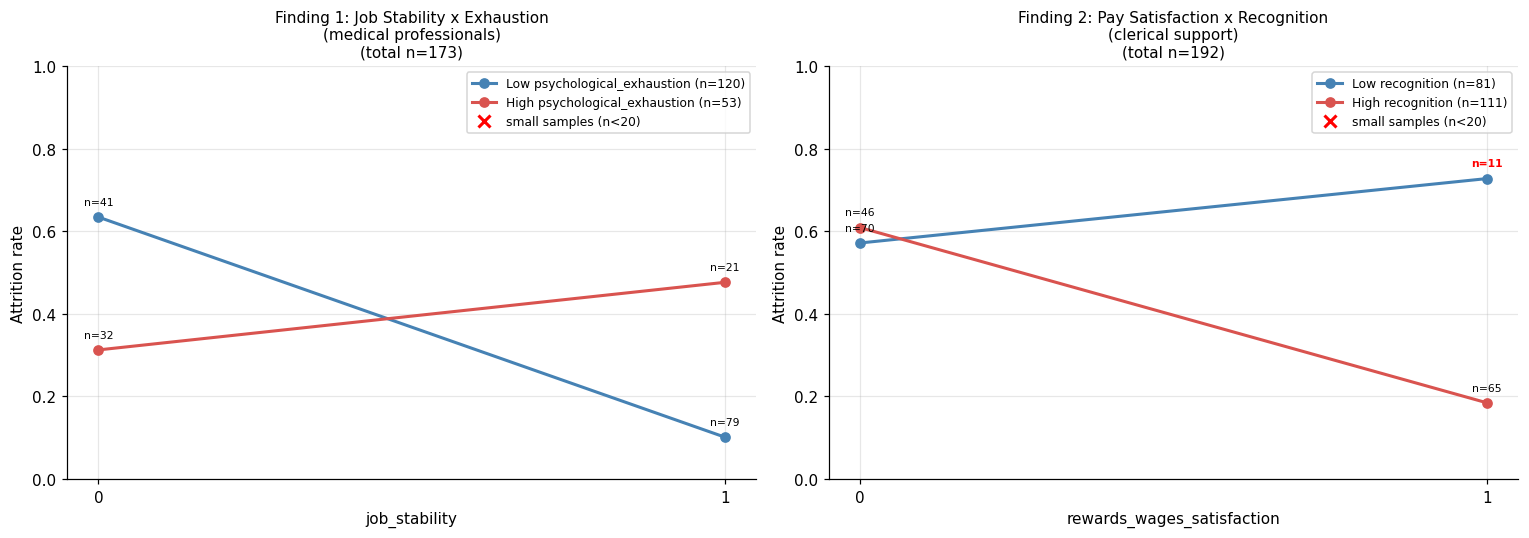

In [109]:
# 4.2 Simple slopes for the 2 significant interactions

def split_buf(sub, buf):
    """Median split for continuous, value split for binary."""
    if sub[buf].nunique() == 2:
        vals = sorted(sub[buf].unique())
        return sub[sub[buf] == vals[0]], sub[sub[buf] == vals[1]]
    med = sub[buf].median()
    return sub[sub[buf] <= med], sub[sub[buf] > med]

def plot_simple_slopes(sub, driver, buffer, title, ax):
    low, high = split_buf(sub, buffer)
    vals = sorted(sub[driver].unique())

    for label, part, color in [(f'Low {buffer}', low, BLUE),
                               (f'High {buffer}', high, RED)]:
        ns = [len(part[part[driver] == v]) for v in vals]
        rates = [part[part[driver] == v][PAST_ATTRITION].mean() for v in vals]
        ax.plot(vals, rates, marker='o', lw=2, color=color,
                label=f'{label} (n={len(part)})')
        for x, y, n in zip(vals, rates, ns):
            tag = f'n={n}' 
            ax.annotate(tag, (x, y), textcoords='offset points',
                        xytext=(0, 8), ha='center', fontsize=7,
                        color='black' if n >= 20 else 'red',
                        fontweight='normal' if n >= 20 else 'bold')
    ax.set_xlabel(driver)
    ax.set_ylabel('Attrition rate')
    ax.set_ylim(0, 1)
    ax.set_xticks(vals)
    ax.set_title(f'{title}\n(total n={len(sub)})', fontsize=10)

    handles, labels = ax.get_legend_handles_labels()
    dummy, = ax.plot([], [], linestyle='none', marker='x',
                     color='red', markersize=8, markeredgewidth=2)
    handles.append(dummy)
    labels.append('small samples (n<20)')
    ax.legend(handles, labels, fontsize=8, loc='best')
    ax.grid(alpha=0.3)



fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Finding 1: medical professionals, stability x exhaustion
sub = df[(df['sector_group'] == 'medical sector') &
         (df['major_group_isco'] == 'professionals')]
plot_simple_slopes(sub,
                   driver='job_stability',
                   buffer='psychological_exhaustion',
                   title='Finding 1: Job Stability x Exhaustion\n(medical professionals)',
                   ax=axes[0])

# Finding 2: clerical support, RWS x recognition
sub = df[df['major_group_isco'] == 'clerical support']
plot_simple_slopes(sub,
                   driver='rewards_wages_satisfaction',
                   buffer='recognition',
                   title='Finding 2: Pay Satisfaction x Recognition\n(clerical support)',
                   ax=axes[1])

plt.tight_layout()
plt.show()

Samples: 1191, Features: 25
Class balance: 43.2% attrition
Dummy baseline AUC: 0.500

LR ROC-AUC: 0.784
RF ROC-AUC: 0.821

 LR Classification Report (threshold 0.5) 
              precision    recall  f1-score   support

No Attrition       0.77      0.71      0.74       676
   Attrition       0.65      0.72      0.69       515

    accuracy                           0.71      1191
   macro avg       0.71      0.71      0.71      1191
weighted avg       0.72      0.71      0.71      1191

 RF Classification Report (threshold 0.5) 
              precision    recall  f1-score   support

No Attrition       0.81      0.70      0.75       676
   Attrition       0.67      0.78      0.72       515

    accuracy                           0.74      1191
   macro avg       0.74      0.74      0.73      1191
weighted avg       0.75      0.74      0.74      1191



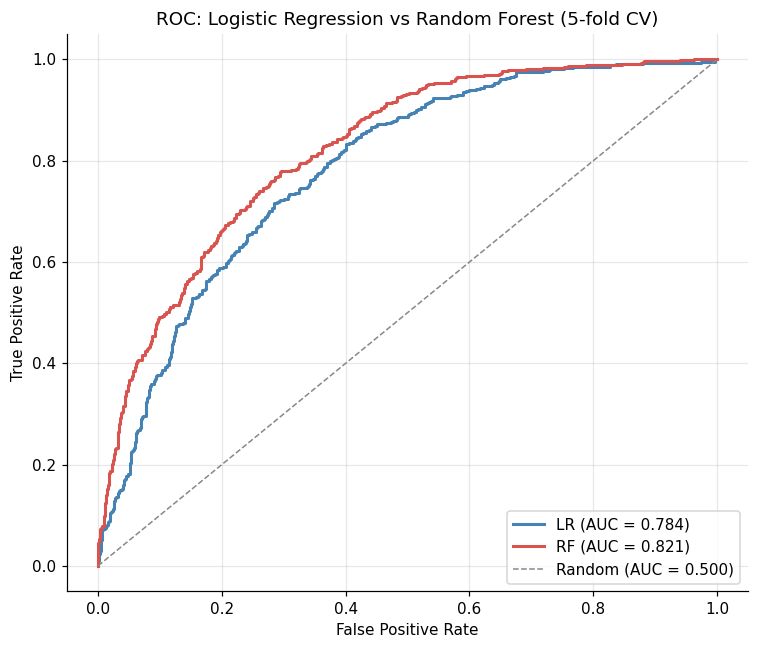

In [110]:
# 5. Classification Performance (LR vs RF ROC)

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_curve, auc, classification_report,
                             confusion_matrix)

# Compact numeric feature set (avoid high-cardinality categoricals)
X = df[FEATURES].fillna(df[FEATURES].median())
y = df[PAST_ATTRITION]

print(f"Samples: {len(X)}, Features: {X.shape[1]}")
print(f"Class balance: {y.mean():.1%} attrition")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42)
)

rf = RandomForestClassifier(
    n_estimators=500,
    min_samples_leaf=10,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

lr_proba = cross_val_predict(lr, X, y, cv=cv, method='predict_proba')[:, 1]
rf_proba = cross_val_predict(rf, X, y, cv=cv, method='predict_proba')[:, 1]

fpr_lr, tpr_lr, _ = roc_curve(y, lr_proba)
fpr_rf, tpr_rf, _ = roc_curve(y, rf_proba)
auc_lr = auc(fpr_lr, tpr_lr)
auc_rf = auc(fpr_rf, tpr_rf)

dummy = DummyClassifier(strategy='most_frequent').fit(X, y)
dummy_auc = roc_auc_score(y, dummy.predict_proba(X)[:, 1])
print(f"Dummy baseline AUC: {dummy_auc:.3f}")

print(f"\nLR ROC-AUC: {auc_lr:.3f}")
print(f"RF ROC-AUC: {auc_rf:.3f}")

lr_pred = (lr_proba >= 0.5).astype(int)
rf_pred = (rf_proba >= 0.5).astype(int)

print("\n LR Classification Report (threshold 0.5) ")
print(classification_report(y, lr_pred,
                            target_names=['No Attrition', 'Attrition']))
print(" RF Classification Report (threshold 0.5) ")
print(classification_report(y, rf_pred,
                            target_names=['No Attrition', 'Attrition']))

# ROC curves
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr_lr, tpr_lr, color=BLUE, lw=2, label=f'LR (AUC = {auc_lr:.3f})')
ax.plot(fpr_rf, tpr_rf, color=RED,  lw=2, label=f'RF (AUC = {auc_rf:.3f})')
ax.plot([0, 1], [0, 1], color=GRAY, ls='--', lw=1, label='Random (AUC = 0.500)')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC: Logistic Regression vs Random Forest (5-fold CV)')
ax.legend(loc='lower right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

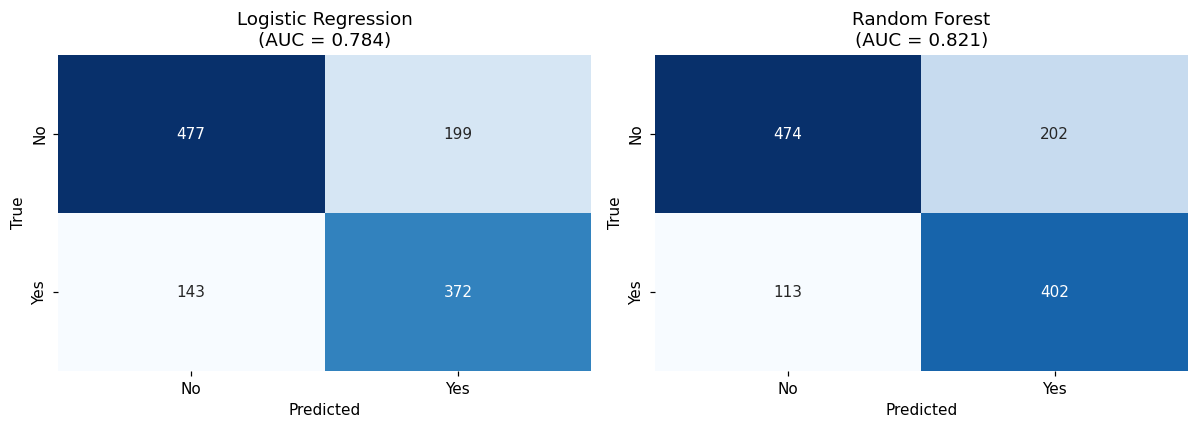

 Threshold sweep (top F1 per model) 

LR top 3 by F1:
model  threshold  precision  recall    f1
   LR       0.40      0.612   0.831 0.705
   LR       0.35      0.584   0.874 0.700
   LR       0.30      0.565   0.917 0.699

RF top 3 by F1:
model  threshold  precision  recall    f1
   RF       0.40      0.593   0.924 0.722
   RF       0.50      0.666   0.781 0.718
   RF       0.45      0.620   0.845 0.715


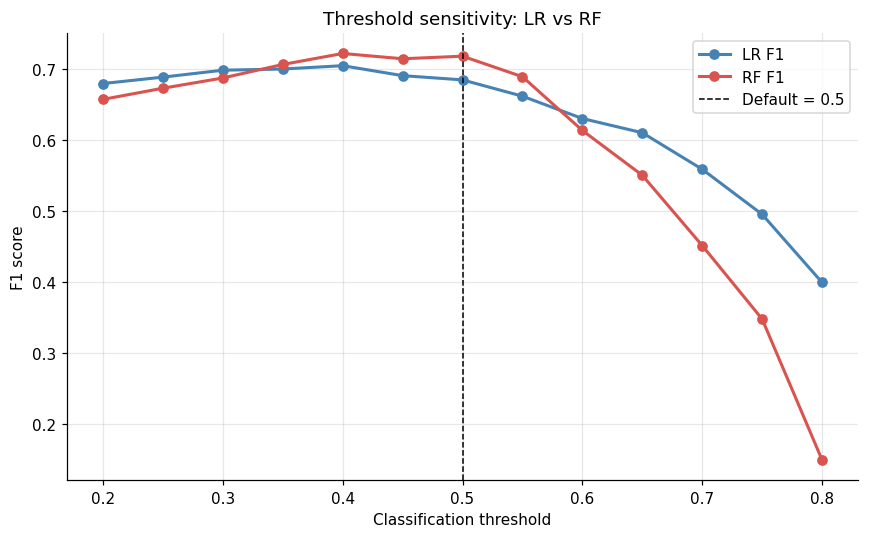

In [111]:
# 5.1 Confusion matrices + threshold sensitivity

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, pred, title, auc_ in zip(
    axes,
    [lr_pred, rf_pred],
    ['Logistic Regression', 'Random Forest'],
    [auc_lr, auc_rf],
):
    cm = confusion_matrix(y, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'],
                cbar=False)
    ax.set_title(f'{title}\n(AUC = {auc_:.3f})')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')

plt.tight_layout()
plt.show()

# Threshold sweep (recall vs precision trade-off)
thresholds = np.arange(0.20, 0.81, 0.05)
rows = []
for t in thresholds:
    for name, proba in [('LR', lr_proba), ('RF', rf_proba)]:
        pred = (proba >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
        prec = tp / (tp + fp) if (tp + fp) > 0 else 0
        rec  = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1   = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0
        rows.append({'model': name, 'threshold': round(t, 2),
                     'precision': prec, 'recall': rec, 'f1': f1})

thr_df = pd.DataFrame(rows)
print(" Threshold sweep (top F1 per model) ")
for name in ['LR', 'RF']:
    best = thr_df[thr_df['model'] == name].sort_values('f1', ascending=False).head(3)
    print(f"\n{name} top 3 by F1:")
    print(best.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
for name, color in [('LR', BLUE), ('RF', RED)]:
    sub = thr_df[thr_df['model'] == name]
    ax.plot(sub['threshold'], sub['f1'], marker='o',
            lw=2, color=color, label=f'{name} F1')
ax.axvline(0.5, color='black', ls='--', lw=1, label='Default = 0.5')
ax.set_xlabel('Classification threshold')
ax.set_ylabel('F1 score')
ax.set_title('Threshold sensitivity: LR vs RF')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Cross-validated Permutation Importance (5-fold) 
                  variable  imp_mean_cv  imp_std_cv
         job_opportunities       0.1224      0.0021
      years_experience_mid       0.0530      0.0105
      emotional_commitment       0.0139      0.0071
             job_stability       0.0128      0.0077
        deserved_promotion       0.0075      0.0047
               job_support       0.0050      0.0016
  psychological_exhaustion       0.0049      0.0043
            job_engagement       0.0047      0.0019
        monthly_salary_mid       0.0041      0.0037
         work_life_balance       0.0039      0.0033
                    gender       0.0029      0.0045
                   age_mid       0.0024      0.0019
          distance_to_work       0.0012      0.0014
               recognition       0.0011      0.0012
             health_issues       0.0007      0.0016
rewards_wages_satisfaction       0.0004      0.0049
           unpaid_overtime       0.0004      0.0049
           phys

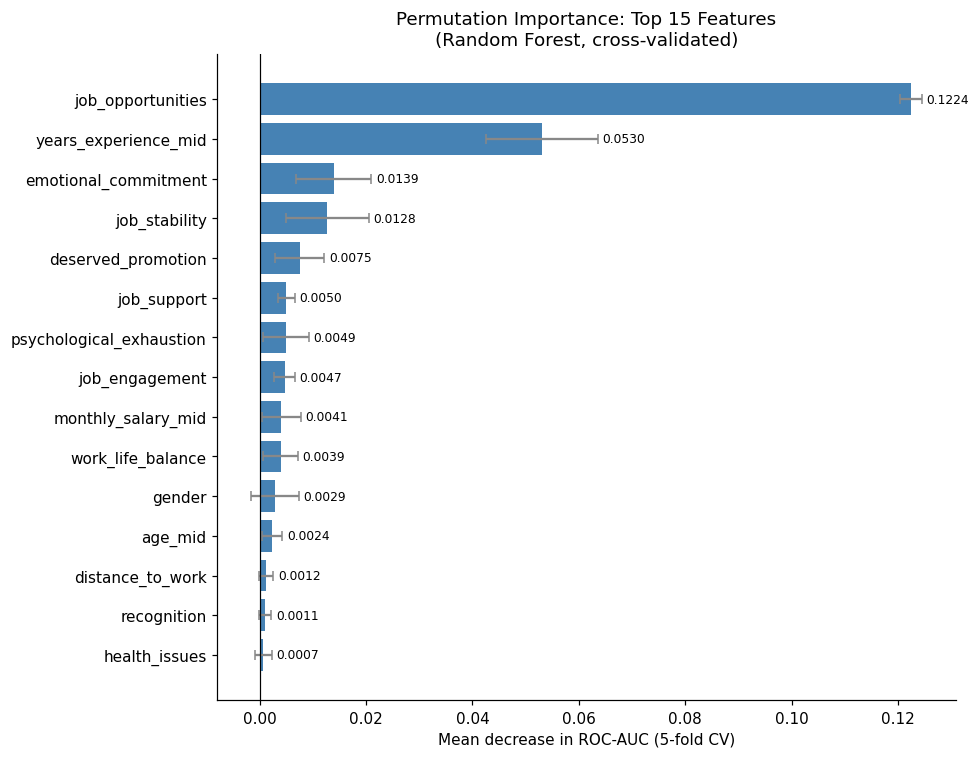

In [112]:
# 5.2 CV permutation importance

from sklearn.inspection import permutation_importance

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

imp_runs = []
for fold, (train_idx, test_idx) in enumerate(cv.split(X, y)):
    rf_fold = RandomForestClassifier(
        n_estimators=500,
        min_samples_leaf=10,
        class_weight='balanced',
        random_state=42 + fold,
        n_jobs=-1,
    )
    rf_fold.fit(X.iloc[train_idx], y.iloc[train_idx])

    perm_fold = permutation_importance(
        rf_fold,
        X.iloc[test_idx], y.iloc[test_idx],
        n_repeats=20,
        random_state=42 + fold,
        scoring='roc_auc',
        n_jobs=-1,
    )
    imp_runs.append(perm_fold.importances_mean)

imp_cv = pd.DataFrame(imp_runs, columns=FEATURES)
perm_cv = pd.DataFrame({
    'variable': FEATURES,
    'imp_mean_cv': imp_cv.mean(axis=0).values,
    'imp_std_cv':  imp_cv.std(axis=0).values,
}).sort_values('imp_mean_cv', ascending=False).reset_index(drop=True)

print("Cross-validated Permutation Importance (5-fold) ")
print(perm_cv.round(4).to_string(index=False))

# Plot Top 15
plot_perm = perm_cv.head(15).sort_values('imp_mean_cv', ascending=True)

fig, ax = plt.subplots(figsize=(9, 7))
bars = ax.barh(
    plot_perm['variable'],
    plot_perm['imp_mean_cv'],
    xerr=plot_perm['imp_std_cv'],
    color=BLUE,
    error_kw={'ecolor': GRAY, 'capsize': 3},
)
ax.axvline(0, color='black', lw=0.8)
ax.bar_label(
    bars,
    labels=[f'{v:.4f}' for v in plot_perm['imp_mean_cv']],
    padding=3, fontsize=8,
)
ax.set_xlabel('Mean decrease in ROC-AUC (5-fold CV)')
ax.set_title('Permutation Importance: Top 15 Features\n(Random Forest, cross-validated)')
plt.tight_layout()
plt.show()

In [113]:
# 6. Triangulation Matrix & Tier Judgment

# Spearman r > 0.1 & FDR-p < 0.05
eda_results = []
for col in FEATURES:
    r, p = spearmanr(df[col], df[PAST_ATTRITION])
    eda_results.append({'Feature': col, 'EDA_r': r, 'EDA_p': p})

eda_df = pd.DataFrame(eda_results)
eda_df['EDA_p_fdr'] = multipletests(eda_df['EDA_p'], method='fdr_bh')[1]
eda_df['EDA_Sig'] = ((eda_df['EDA_r'].abs() >= 0.1) & (eda_df['EDA_p_fdr'] < 0.05)).astype(int)

#  CART (1=use, 0=no use)
tree = cart.tree_
cart_features_used = set()
for node in range(tree.node_count):
    if tree.feature[node] != -2:
        cart_features_used.add(cart_cols[tree.feature[node]])
cart_used = {f: 1 if f in cart_features_used else 0 for f in FEATURES}

# combine 4 evidences
tri_df = eda_df[['Feature', 'EDA_Sig', 'EDA_r']].copy()
tri_df['Logit_p'] = [coef_core.loc[f, 'p_fdr'] if f in coef_core.index else 1.0 for f in FEATURES]
tri_df['RF_Imp'] = [perm_cv.loc[perm_cv['variable'] == f, 'imp_mean_cv'].values[0] if f in perm_cv['variable'].values else 0.0 for f in FEATURES]
tri_df['CART_Used'] = [cart_used[f] for f in FEATURES]

tri_df['Logit_Sig'] = (tri_df['Logit_p'] < 0.05).astype(int)
tri_df['RF_Sig'] = (tri_df['RF_Imp'] > 0.01).astype(int)

# total evidence scores
tri_df['Evidence_Score'] = tri_df['EDA_Sig'] + tri_df['Logit_Sig'] + tri_df['RF_Sig'] + tri_df['CART_Used']


def assign_tier(score):
    if score == 4: return 'Tier 1 (Core)'
    elif score == 3: return 'Tier 2 (Strong)'
    elif score == 2: return 'Tier 3 (Moderate)'
    else: return 'Tier 4 (Weak)'

tri_df['Tier'] = tri_df['Evidence_Score'].apply(assign_tier)
tri_df = tri_df.sort_values(by=['Evidence_Score', 'RF_Imp'], ascending=[False, False]).reset_index(drop=True)

# Table
final_table = tri_df.head(15)[['Feature', 'Tier', 'EDA_r', 'EDA_Sig', 'Logit_Sig', 'RF_Sig', 'CART_Used', 'RF_Imp']]
final_table.columns = ['Feature', 'Evidence Tier', 'EDA r', 'EDA Sig', 'Logit Sig', 'RF Sig', 'CART Used', 'RF Imp']

print("Triangulation Results: Final Evidence Matrix ")
print(final_table.round(4).to_string(index=False))

Triangulation Results: Final Evidence Matrix 
                   Feature   Evidence Tier   EDA r  EDA Sig  Logit Sig  RF Sig  CART Used  RF Imp
         job_opportunities   Tier 1 (Core)  0.3493        1          1       1          1  0.1224
      years_experience_mid   Tier 1 (Core)  0.1372        1          1       1          1  0.0530
      emotional_commitment   Tier 1 (Core) -0.2312        1          1       1          1  0.0139
             job_stability   Tier 1 (Core) -0.2536        1          1       1          1  0.0128
        deserved_promotion Tier 2 (Strong) -0.2389        1          1       0          1  0.0075
            job_engagement Tier 2 (Strong) -0.1582        1          1       0          1  0.0047
               job_support   Tier 4 (Weak) -0.1822        1          0       0          0  0.0050
  psychological_exhaustion   Tier 4 (Weak)  0.1537        1          0       0          0  0.0049
         work_life_balance   Tier 4 (Weak) -0.1573        1          0  

## Limitations & Next Steps

*   **Cross-sectional snapshot**: Data shows strong associations, but not strict causation.
*   **Predictive scope**: AUC ~0.82 is solid for HR risk ranking, but it’s a decision-support tool, not for automated high-stakes decisions.
*   **Subgroup interactions**: Small sample sizes (e.g., clerical staff) caused quasi-separation. Findings need validation via qualitative exit interviews.
*   **Next Steps**: 
    *   Track longitudinally to observe attitude shifts.
    *   Include performance metrics to specifically predict **high-performer turnover**.
    *   Integrate dynamic engagement surveys and external market data.
    *   Monitor **Model Drift** to prevent performance degradation over time.